Baseline LR model

* C3-CZ
* Hjorth

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.stats import skew

DATA = Path('eeg_starter/data')
FS = 64 # hz
montage = ['FP1-F7', 'F7-T3', 'T3-T5', 'T5-O1', 'FP2-F8', 'F8-T4',
           'T4-T6',  'T6-O2', 'T3-C3', 'C3-CZ',  'CZ-C4',
           'C4-T4',  'FP1-F3','F3-C3', 'C3-P3',  'P3-O1',
           'FP2-F4', 'F4-C4', 'C4-P4', 'P4-O2'] # channels
CH_NAME = 'C3-CZ'
CH = montage.index(CH_NAME)

train_seg = torch.load(DATA / 'segments_h1k_train.pt')
age_train = np.array([s[3] for s in train_seg])
files_train = [s[4] for s in train_seg]
print(f'{len(train_seg)} training subjects, channel {CH_NAME} (index {CH})')

825 training subjects, channel C3-CZ (index 9)


"feature_extraction" sýndi skekkju í gögnunum, log til að laga?

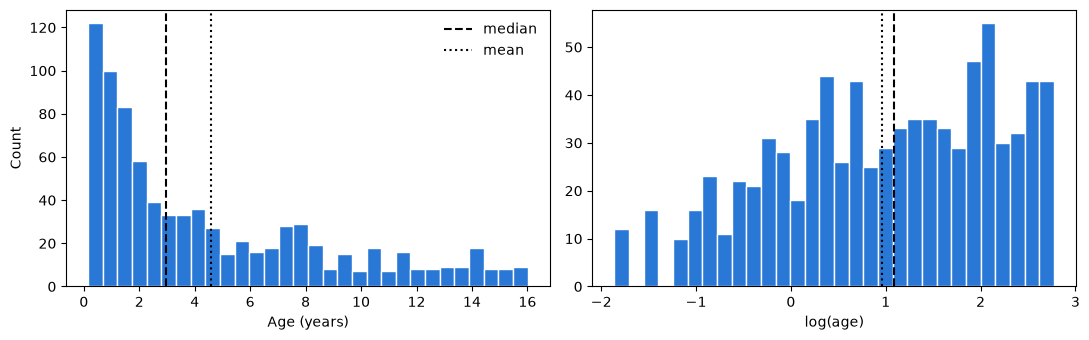

,mean,median,SD
age (years),4.59,2.98,4.30
log(age),0.97,1.09,1.18


In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, values, label in [(ax[0], age_train, 'Age (years)'), (ax[1], np.log(age_train), 'log(age)')]:
    a.hist(values, bins=30, color='#2a78d6', edgecolor='white')
    a.axvline(np.median(values), color='k', ls='--', label='median')
    a.axvline(values.mean(), color='k', ls=':', label='mean')
    a.set_xlabel(label)
ax[0].set_ylabel('Count'); ax[0].legend(frameon=False)
plt.tight_layout(); plt.show()

pd.DataFrame({name: {'mean': v.mean(), 'median': np.median(v), 'SD': v.std(ddof=1)} for name, v in [('age (years)', age_train), ('log(age)', np.log(age_train))]}).T.round(2)

yurr

checka tíma og features

fyrstu 300s eiga að vera mikilvægastar

In [3]:
WIN_S = 30
WIN = WIN_S * FS
N_WIN = 900 // WIN_S

def hjorth(w):
    dx = np.diff(w, axis=1)
    ddx = np.diff(dx, axis=1)
    var_x, var_dx, var_ddx = w.var(axis=1), dx.var(axis=1), ddx.var(axis=1)
    flat = var_x < 1e-6
    with np.errstate(divide='ignore', invalid='ignore'):
        act = np.log(var_x)
        mob = np.sqrt(var_dx / var_x)
        comp = np.sqrt(var_ddx / var_dx) / mob
    for f in (act, mob, comp):
        f[flat] = np.nan
    return act, mob, comp

FEATURES = ['log activity', 'mobility', 'complexity']
feats = np.full((len(files_train), N_WIN, 3), np.nan)

for i, fname in enumerate(files_train):
    eeg = torch.load(DATA / 'pre_processed' / fname.replace('.edf', '.pt'))
    x = eeg[CH].double().numpy()
    windows = x[:N_WIN * WIN].reshape(N_WIN, WIN)
    feats[i] = np.stack(hjorth(windows), axis=1)

print('feature array (subjects, windows, features):', feats.shape)
print('undefined (flat) windows:', int(np.isnan(feats[..., 0]).sum()))

feature array (subjects, windows, features): (825, 30, 3)
undefined (flat) windows: 59


In [4]:
def corr(a, b):
    ok = ~np.isnan(a)
    return np.corrcoef(a[ok], b[ok])[0, 1]

t_mid = (np.arange(N_WIN) + 0.5) * WIN_S
r_age = np.array([[corr(feats[:, w, f], age_train) for w in range(N_WIN)] for f in range(3)])
r_log = np.array([[corr(feats[:, w, f], np.log(age_train)) for w in range(N_WIN)] for f in range(3)])

In [5]:
pd.DataFrame({
    'mean r (age), 0-300 s':       r_age[:, t_mid < 300].mean(axis=1),
    'mean r (age), 300-900 s':     r_age[:, t_mid > 300].mean(axis=1),
    'mean r (log age), 0-300 s':   r_log[:, t_mid < 300].mean(axis=1),
    'mean r (log age), 300-900 s': r_log[:, t_mid > 300].mean(axis=1),
}, index=FEATURES).round(3)

,"mean r (age), 0-300 s","mean r (age), 300-900 s","mean r (log age), 0-300 s","mean r (log age), 300-900 s"
log activity,-0.716,-0.640,-0.622,-0.461
mobility,0.657,0.499,0.656,0.392
complexity,-0.323,-0.317,-0.355,-0.282


fyrstu 300s og droppa complexity

In [ ]:
def subject_features(segments):
    out = np.full((len(segments), 2), np.nan)
    n_reg = 300 // WIN_S
    for i, s in enumerate(segments):
        eeg = torch.load(DATA / 'pre_processed' / s[4].replace('.edf', '.pt'))
        x = eeg[CH].double().numpy()
        act, mob, _ = hjorth(x[:n_reg * WIN].reshape(n_reg, WIN))
        out[i] = np.nanmedian(act), np.nanmedian(mob)
    return out

val_seg = torch.load(DATA / 'segments_h1k_val.pt')
age_val = np.array([s[3] for s in val_seg])

X_train = subject_features(train_seg)
X_val = subject_features(val_seg)
y_train, y_val = np.log(age_train), np.log(age_val)
print('train', X_train.shape, ' val', X_val.shape, ' undefined:', int(np.isnan(X_val).sum()))

train (825, 2)  val (103, 2)  undefined: 0


In [ ]:
mu, sd = X_train.mean(axis=0), X_train.std(axis=0)

def design(X, cols):
    Z = (X[:, cols] - mu[cols]) / sd[cols]
    return np.column_stack([np.ones(len(Z)), Z])

def fit(X, y, cols):
    theta, *_ = np.linalg.lstsq(design(X, cols), y, rcond=None)
    return theta

def rmse(a, b):
    return np.sqrt(np.mean((a - b) ** 2))

In [8]:
cols = [0, 1]
theta = fit(X_train, y_train, cols)
pred_train = np.exp(design(X_train, cols) @ theta)
pred_val = np.exp(design(X_val, cols) @ theta)

print('Coefficients (standardised features):')
print(f'  intercept     {theta[0]: .3f}')
print(f'  log activity  {theta[1]: .3f}')
print(f'  mobility      {theta[2]: .3f}')

def r2(y, p):
    return 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2)

res = pd.DataFrame({
    'RMSE (years)': [rmse(pred_train, age_train), rmse(pred_val, age_val)],
    'MAE (years)':  [np.mean(np.abs(pred_train - age_train)), np.mean(np.abs(pred_val - age_val))],
    'R^2 (log age)': [r2(y_train, np.log(pred_train)), r2(y_val, np.log(pred_val))],
}, index=['train', 'validation']).round(3)
res

Coefficients (standardised features):
  intercept      0.966
  log activity  -0.372
  mobility       0.556


,RMSE (years),MAE (years),R^2 (log age)
train,2.847,1.889,0.555
validation,2.178,1.634,0.532


Val hærra en train? lítið dataset??